<a href="https://colab.research.google.com/github/Sajidnihal52/Deep-Learning-Framework-for-Underwater-Marine-Organism-Classification-and-Biodiversity-Monitoring/blob/main/UWI2020_Robustness_WhiteBalance_Evaluation_Only.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UWI-2020 — White-balance and robustness evaluation ONLY

This notebook **does not train a model**. It loads your already-trained HM-SA-Net checkpoint and evaluates it on:
- Original test images
- White-balanced test images
- Brightness and contrast changes
- Gaussian noise and blur
- Underwater-style color shifts

## Before running
1. Upload your already-trained model checkpoint (`.pt` or `.pth`) when prompted.
2. Upload your dataset ZIP, or change the Google Drive option to point to your ZIP.
3. Select **Runtime → Change runtime type → GPU** if available.
4. Run cells from top to bottom.

The checkpoint must contain a `model_state_dict` compatible with the HM-SA-Net architecture below. If your original training saved only a plain state dict or used a different architecture, adjust the checkpoint loading cell to match that model.

The test folder should be `dataset/test/class_name/image.jpg`. If the dataset has only class folders, the notebook creates a stratified held-out test split, but using your original test set is preferable.


In [ ]:
from pathlib import Path
import zipfile, shutil
from google.colab import files

# Upload dataset ZIP
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_PATH = "/content/drive/MyDrive/UWI2020.zip"  # edit this path
    EXTRACT_DIR = Path("/content/dataset_upload")
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)
else:
    uploaded = files.upload()
    zips = [name for name in uploaded if name.lower().endswith(".zip")]
    if not zips:
        raise ValueError("Upload a dataset .zip file.")
    ZIP_PATH = "/content/" + zips[0]
    EXTRACT_DIR = Path("/content/dataset_upload")
    if EXTRACT_DIR.exists():
        shutil.rmtree(EXTRACT_DIR)
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

def is_dataset_root(p):
    p = Path(p)
    if (p / "test").is_dir() and len([x for x in (p/"test").iterdir() if x.is_dir()]) >= 2:
        return True
    if (p / "train").is_dir() and len([x for x in (p/"train").iterdir() if x.is_dir()]) >= 2:
        return True
    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    dirs = [x for x in p.iterdir() if x.is_dir() and x.name.lower() not in {"train","test","valid","val","__macosx"}]
    return len(dirs) >= 2 and any(f.is_file() and f.suffix.lower() in image_exts for d in dirs for f in d.rglob("*"))

DATASET_ROOT = None
for p in [EXTRACT_DIR] + [x for x in EXTRACT_DIR.rglob("*") if x.is_dir()]:
    if is_dataset_root(p):
        DATASET_ROOT = Path(p)
        break
if DATASET_ROOT is None:
    raise FileNotFoundError("Dataset folder not found. Expected test/class_name/images or class_name/images.")
print("Dataset root:", DATASET_ROOT)
print("Top-level:", [p.name for p in DATASET_ROOT.iterdir()])

# Upload already-trained checkpoint
uploaded_model = files.upload()
checkpoints = [name for name in uploaded_model if name.lower().endswith((".pt", ".pth"))]
if not checkpoints:
    raise ValueError("Upload your trained model checkpoint (.pt or .pth).")
CHECKPOINT_PATH = Path("/content") / checkpoints[0]
print("Checkpoint:", CHECKPOINT_PATH)


Saving archive.zip to archive.zip
Dataset root: /content/dataset_upload
Top-level: ['cls_crops', 'archive']


Saving best_hybrid_attention_model.pth to best_hybrid_attention_model.pth
Checkpoint: /content/best_hybrid_attention_model.pth


## Step 2 — Imports and settings


In [ ]:
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance, ImageFilter
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

OUT = Path("/content/hm_sa_whitebalance_robustness_results")
OUT.mkdir(parents=True, exist_ok=True)
IMAGE_SIZE = 224
BATCH_SIZE = 8
WORKERS = 2
SEED = 42
USE_AMP = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


## Step 3 — White balancing, corruptions, and model architecture
The architecture below is included only so the existing checkpoint can be reconstructed for inference. No optimizer or training loop is used.


In [ ]:
def gray_world(img):
    a = np.asarray(img.convert("RGB")).astype(np.float32)
    means = a.mean((0, 1))
    target = means.mean()
    a *= (target / np.maximum(means, 1.0)).reshape(1, 1, 3)
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

class WB:
    def __call__(self, img):
        return gray_world(img)

class Corruption:
    def __init__(self, kind, severity):
        self.kind, self.severity = kind, severity
    def __call__(self, img):
        img = img.convert("RGB")
        s = self.severity
        if self.kind == "white_balance":
            return gray_world(img)
        if self.kind == "brightness":
            return ImageEnhance.Brightness(img).enhance({1:.70, 2:.85, 3:1.15, 4:1.30}[s])
        if self.kind == "contrast":
            return ImageEnhance.Contrast(img).enhance({1:.60, 2:.80, 3:1.20, 4:1.40}[s])
        if self.kind == "gaussian_blur":
            return img.filter(ImageFilter.GaussianBlur({1:.5, 2:1.0, 3:1.5, 4:2.0}[s]))
        if self.kind == "gaussian_noise":
            a = np.asarray(img).astype(np.float32)
            rng = np.random.default_rng(SEED + 100*s)
            a += rng.normal(0, {1:5, 2:10, 3:20, 4:30}[s], a.shape)
            return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
        if self.kind == "color_shift":
            a = np.asarray(img).astype(np.float32)
            _, g, b = {1:(0,5,10), 2:(0,10,25), 3:(0,20,40), 4:(0,30,55)}[s]
            a[...,1] += g
            a[...,2] += b
            return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
        return img

def transform_for(white_balance=False, corruption=None, severity=0):
    ops = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]
    if white_balance:
        ops.append(WB())
    if corruption:
        ops.append(Corruption(corruption, severity))
    ops += [
        transforms.ToTensor(),
        transforms.Normalize([.485,.456,.406], [.229,.224,.225])
    ]
    return transforms.Compose(ops)

class IndexedImages(Dataset):
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, list(indices), transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        image, label = self.base[self.indices[i]]
        return self.transform(image), label

import torch
import torch.nn as nn
from torchvision import models


class ChannelAttention(nn.Module):
    def __init__(self, ch=128):
        super().__init__()
        hidden = max(ch // 16, 1)

        self.mlp = nn.Sequential(
            nn.Conv2d(ch, hidden, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, ch, kernel_size=1, bias=False)
        )

    def forward(self, x):
        avg_features = x.mean(dim=(2, 3), keepdim=True)
        max_features = torch.amax(x, dim=(2, 3), keepdim=True)

        attention = torch.sigmoid(
            self.mlp(avg_features) + self.mlp(max_features)
        )

        return x * attention


class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(
            2, 1, kernel_size=7, padding=3, bias=False
        )

    def forward(self, x):
        avg_features = x.mean(dim=1, keepdim=True)
        max_features = torch.amax(x, dim=1, keepdim=True)

        attention = torch.sigmoid(
            self.conv(torch.cat([avg_features, max_features], dim=1))
        )

        return x * attention


class HM_SANet(nn.Module):
    def __init__(self, n_classes, pretrained=False, ch=128):
        super().__init__()

        # Backbone feature extractors
        eff_weights = (
            models.EfficientNet_V2_S_Weights.DEFAULT
            if pretrained else None
        )
        cnx_weights = (
            models.ConvNeXt_Tiny_Weights.DEFAULT
            if pretrained else None
        )

        self.eff_features = models.efficientnet_v2_s(
            weights=eff_weights
        ).features

        self.cnx_features = models.convnext_tiny(
            weights=cnx_weights
        ).features

        # Project both backbones to 128 channels
        self.eff_proj = nn.Sequential(
            nn.Conv2d(1280, ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(ch),
            nn.GELU()
        )

        self.cnx_proj = nn.Sequential(
            nn.Conv2d(768, ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(ch),
            nn.GELU()
        )

        # Feature fusion
        self.fusion = nn.Sequential(
            nn.Conv2d(ch * 2, ch * 2, kernel_size=3,
                      padding=1, bias=False),
            nn.BatchNorm2d(ch * 2),
            nn.GELU(),
            nn.Conv2d(ch * 2, ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(ch),
            nn.GELU()
        )

        # Attention modules
        self.ca = ChannelAttention(ch)
        self.sa = SpatialAttention()

        # Feature refinement
        self.refine = nn.Sequential(
            nn.Conv2d(ch, ch, kernel_size=3,
                      padding=1, bias=False),
            nn.BatchNorm2d(ch),
            nn.GELU()
        )

        # Pooling and classification
        self.pool = nn.AdaptiveAvgPool2d(1)

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(ch, 256),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(256, n_classes)
        )

    def forward(self, x):
        eff = self.eff_proj(self.eff_features(x))
        cnx = self.cnx_proj(self.cnx_features(x))

        # Combine features
        f = self.fusion(torch.cat([eff, cnx], dim=1))

        # Apply channel and spatial attention
        f = self.ca(f)
        f = self.sa(f)

        # Refine and classify
        f = f + self.refine(f)
        f = self.pool(f)

        return self.head(f)

def get_test_data():
    test_dir = DATASET_ROOT / "test"
    train_dir = DATASET_ROOT / "train"
    if test_dir.is_dir():
        test = datasets.ImageFolder(str(test_dir), transform=None)
        classes = test.classes
        if train_dir.is_dir():
            train = datasets.ImageFolder(str(train_dir), transform=None)
            if train.classes != classes:
                raise ValueError(f"Train/test class order mismatch: {train.classes} vs {classes}")
        return test, np.arange(len(test)), classes
    if train_dir.is_dir():
        base = datasets.ImageFolder(str(train_dir), transform=None)
    else:
        base = datasets.ImageFolder(str(DATASET_ROOT), transform=None)
    if len(base.classes) < 2:
        raise RuntimeError("Could not find at least two class folders.")
    labels = np.array([y for _, y in base.samples])
    _, test_idx = train_test_split(np.arange(len(labels)), test_size=0.15,
                                   random_state=SEED, stratify=labels)
    print("WARNING: No dedicated test folder found; using a stratified 15% split.")
    return base, test_idx, base.classes

def loader(base, idx, tf):
    return DataLoader(IndexedImages(base,idx,tf), batch_size=BATCH_SIZE, shuffle=False,
                      num_workers=WORKERS, pin_memory=torch.cuda.is_available(),
                      persistent_workers=WORKERS > 0)

@torch.no_grad()
def predict(model, dl):
    model.eval()
    ys, ps = [], []
    for x,y in dl:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type,
                            enabled=(USE_AMP and DEVICE.type=="cuda")):
            logits = model(x)
        ys.extend(y.numpy().tolist())
        ps.extend(logits.argmax(1).cpu().numpy().tolist())
    return np.asarray(ys), np.asarray(ps)

def get_metrics(y, p, classes):
    pr, re, f1, _ = precision_recall_fscore_support(
        y, p, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(y,p),
        "macro_precision": pr,
        "macro_recall": re,
        "macro_f1": f1
    }

def load_trained_model(classes):
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )

    if "model_state_dict" not in checkpoint:
        raise ValueError(
            "Expected model_state_dict in the checkpoint."
        )

    state = checkpoint["model_state_dict"]

    # Your checkpoint stores the labels under class_names.
    saved_classes = checkpoint.get("class_names")

    if saved_classes is not None:
        if list(saved_classes) != list(classes):
            raise ValueError(
                f"Class mismatch!\n"
                f"Checkpoint: {saved_classes}\n"
                f"Dataset: {classes}"
            )

    if checkpoint.get("num_classes", len(classes)) != len(classes):
        raise ValueError("Checkpoint and dataset class counts differ.")

    # Reconstruct the original model without downloading pretrained weights.
    model = HM_SANet(
        n_classes=len(classes),
        pretrained=False,
        ch=128
    )

    # Support checkpoints saved with DataParallel.
    if state and all(k.startswith("module.") for k in state):
        state = {
            k.replace("module.", "", 1): v
            for k, v in state.items()
        }

    # Strict loading verifies that all parameter names and shapes match.
    model.load_state_dict(state, strict=True)

    model = model.to(DEVICE)
    model.eval()

    print("Checkpoint loaded successfully.")
    print("Architecture:", checkpoint.get("architecture"))
    print("Classes:", classes)
    print("Image size:", checkpoint.get("image_size"))

    return model

In [ ]:
test, test_indices, classes = get_test_data()

print("Classes:", classes)
print("Number of test images:", len(test_indices))

model = load_trained_model(classes)

print("Model is ready for evaluation.")

Classes: ['echinus', 'holothurian', 'scallop', 'starfish']
Number of test images: 870
Checkpoint loaded successfully.
Architecture: EfficientNetV2-S + ConvNeXt-Tiny + feature fusion + channel/spatial attention
Classes: ['echinus', 'holothurian', 'scallop', 'starfish']
Image size: 224
Model is ready for evaluation.


In [ ]:
from pathlib import Path

print("Current DATASET_ROOT:", DATASET_ROOT)
print("\nFolders inside DATASET_ROOT:")

for p in DATASET_ROOT.iterdir():
    print("DIR " if p.is_dir() else "FILE", p.name)

print("\nSearching for train/test folders...")
for p in DATASET_ROOT.rglob("*"):
    if p.is_dir() and p.name.lower() in ("train", "test"):
        print("\nFound:", p)
        print("Class folders:", [
            x.name for x in p.iterdir() if x.is_dir()
        ])

Current DATASET_ROOT: /content/dataset_upload

Folders inside DATASET_ROOT:
DIR  cls_crops
DIR  archive

Searching for train/test folders...

Found: /content/dataset_upload/cls_crops/train
Class folders: ['starfish', 'scallop', 'echinus', 'holothurian']

Found: /content/dataset_upload/cls_crops/test
Class folders: ['starfish', 'scallop', 'echinus', 'holothurian']

Found: /content/dataset_upload/archive/cls_crops/train
Class folders: ['starfish', 'scallop', 'echinus', 'holothurian']

Found: /content/dataset_upload/archive/cls_crops/test
Class folders: ['starfish', 'scallop', 'echinus', 'holothurian']


In [ ]:
from pathlib import Path

DATASET_ROOT = Path("/content/dataset_upload/cls_crops")

print("Updated dataset path:", DATASET_ROOT)
print("Train folder exists:", (DATASET_ROOT / "train").is_dir())
print("Test folder exists:", (DATASET_ROOT / "test").is_dir())

Updated dataset path: /content/dataset_upload/cls_crops
Train folder exists: True
Test folder exists: True


In [ ]:
test, test_indices, classes = get_test_data()

print("Dataset classes:", classes)
print("Number of test images:", len(test_indices))

assert set(classes) == {
    "echinus", "holothurian", "scallop", "starfish"
}, f"Unexpected classes: {classes}"

Dataset classes: ['echinus', 'holothurian', 'scallop', 'starfish']
Number of test images: 870


In [ ]:
model = load_trained_model(classes)

print("Model loaded successfully. No retraining performed.")

Checkpoint loaded successfully.
Architecture: EfficientNetV2-S + ConvNeXt-Tiny + feature fusion + channel/spatial attention
Classes: ['echinus', 'holothurian', 'scallop', 'starfish']
Image size: 224
Model loaded successfully. No retraining performed.


In [ ]:
def get_test_data():
    # Check common nested dataset locations
    candidates = [
        DATASET_ROOT / "cls_crops",
        DATASET_ROOT / "archive" / "cls_crops",
        DATASET_ROOT,
    ]

    root = None

    for candidate in candidates:
        if (candidate / "test").is_dir():
            test_classes = [
                p.name for p in (candidate / "test").iterdir()
                if p.is_dir()
            ]
            if len(test_classes) >= 2:
                root = candidate
                break

    if root is None:
        raise FileNotFoundError(
            "Could not find the real dataset test folder. "
            "Inspect the extracted folder structure."
        )

    test_dir = root / "test"
    test = datasets.ImageFolder(str(test_dir), transform=None)
    classes = test.classes

    print("Correct dataset root:", root)
    print("Correct classes:", classes)
    print("Test images:", len(test))

    return test, np.arange(len(test)), classes

## Step 4 — Load the existing checkpoint and evaluate robustness


Classes: ['echinus', 'holothurian', 'scallop', 'starfish']
Number of test images: 870
Checkpoint loaded successfully.
Architecture: EfficientNetV2-S + ConvNeXt-Tiny + feature fusion + channel/spatial attention
Classes: ['echinus', 'holothurian', 'scallop', 'starfish']
Image size: 224
Loaded existing model checkpoint — no training will be performed.
original         severity=0 | accuracy=0.9552 | macro-F1=0.9552
white_balance    severity=0 | accuracy=0.9299 | macro-F1=0.9298
brightness       severity=1 | accuracy=0.9402 | macro-F1=0.9398
brightness       severity=2 | accuracy=0.9506 | macro-F1=0.9504
brightness       severity=3 | accuracy=0.9575 | macro-F1=0.9575
brightness       severity=4 | accuracy=0.9517 | macro-F1=0.9518
contrast         severity=1 | accuracy=0.9598 | macro-F1=0.9597
contrast         severity=2 | accuracy=0.9598 | macro-F1=0.9598
contrast         severity=3 | accuracy=0.9575 | macro-F1=0.9575
contrast         severity=4 | accuracy=0.9540 | macro-F1=0.9541
gaussian_

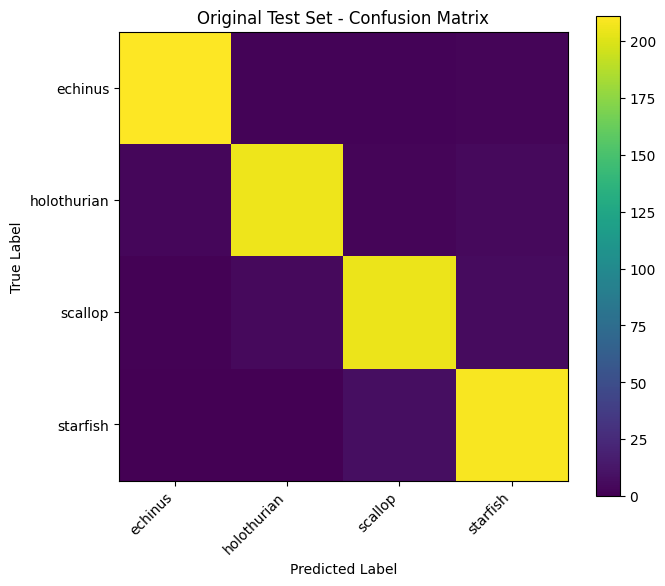


Original vs White Balance:
    condition  accuracy  macro_precision  macro_recall  macro_f1
     original  0.955172         0.955394      0.955170  0.955199
white_balance  0.929885         0.932571      0.929856  0.929847

Saved results to: /content/hm_sa_whitebalance_robustness_results


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix

# 1. Load test data and class names
test, test_indices, classes = get_test_data()

print("Classes:", classes)
print("Number of test images:", len(test_indices))

# 2. Load the existing trained model (no training)
model = load_trained_model(classes)
model.eval()

print("Loaded existing model checkpoint — no training will be performed.")

# 3. Define evaluation conditions
conditions = [
    ("original", False, None, 0),
    ("white_balance", True, None, 0),
]

corruptions = [
    "brightness",
    "contrast",
    "gaussian_noise",
    "gaussian_blur",
    "color_shift",
]

for corruption in corruptions:
    for severity in [1, 2, 3, 4]:
        conditions.append(
            (corruption, False, corruption, severity)
        )

# 4. Evaluate each condition
all_rows = []
original_y = None
original_p = None

for name, wb, corruption, severity in conditions:

    tf = transform_for(
        white_balance=wb,
        corruption=corruption,
        severity=severity,
    )

    dl = loader(test, test_indices, tf)

    y, p = predict(model, dl)

    row = get_metrics(y, p, classes)
    row.update({
        "condition": name,
        "severity": severity,
    })

    all_rows.append(row)

    print(
        f"{name:16s} severity={severity} | "
        f"accuracy={row['accuracy']:.4f} | "
        f"macro-F1={row['macro_f1']:.4f}"
    )

    if name == "original":
        original_y = np.asarray(y)
        original_p = np.asarray(p)

# 5. Create results DataFrame
df = pd.DataFrame(all_rows)

base_row = df.loc[df["condition"] == "original"].iloc[0]
base_acc = float(base_row["accuracy"])
base_f1 = float(base_row["macro_f1"])

df["accuracy_change_pp"] = (
    df["accuracy"] - base_acc
) * 100

df["macro_f1_change_pp"] = (
    df["macro_f1"] - base_f1
) * 100

# 6. Save robustness results
OUT.mkdir(parents=True, exist_ok=True)

df.to_csv(
    OUT / "robustness_evaluation.csv",
    index=False,
)

# 7. Classification report for original test images
report = classification_report(
    original_y,
    original_p,
    labels=np.arange(len(classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(report).T.to_csv(
    OUT / "original_test_classification_report.csv"
)

# 8. Confusion matrix
cm = confusion_matrix(
    original_y,
    original_p,
    labels=np.arange(len(classes)),
)

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm, interpolation="nearest")
fig.colorbar(im, ax=ax)

ax.set_title("Original Test Set - Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_xticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=45, ha="right")

ax.set_yticks(range(len(classes)))
ax.set_yticklabels(classes)

fig.tight_layout()

fig.savefig(
    OUT / "original_test_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# 9. Compare original and white-balance results
print("\nOriginal vs White Balance:")

print(
    df[df["condition"].isin(["original", "white_balance"])][
        [
            "condition",
            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
        ]
    ].to_string(index=False)
)

print("\nSaved results to:", OUT.resolve())


In [ ]:
from collections import Counter

state = checkpoint["model_state_dict"]

# Count parameters by top-level module
prefix_counts = Counter(
    key.split(".")[0] for key in state.keys()
)

print("=== MODEL MODULES ===")
for module, count in prefix_counts.items():
    print(f"{module:25s}: {count} state entries")

print("\n=== NON-EFFICIENTNET PARAMETER NAMES ===")
for key, tensor in state.items():
    if not key.startswith("eff_features."):
        print(f"{key:55s} {tuple(tensor.shape)}")

=== MODEL MODULES ===
eff_features             : 780 state entries
cnx_features             : 178 state entries
eff_proj                 : 6 state entries
cnx_proj                 : 6 state entries
fusion                   : 12 state entries
ca                       : 2 state entries
sa                       : 1 state entries
refine                   : 6 state entries
head                     : 4 state entries

=== NON-EFFICIENTNET PARAMETER NAMES ===
cnx_features.0.0.weight                                 (96, 3, 4, 4)
cnx_features.0.0.bias                                   (96,)
cnx_features.0.1.weight                                 (96,)
cnx_features.0.1.bias                                   (96,)
cnx_features.1.0.layer_scale                            (96, 1, 1)
cnx_features.1.0.block.0.weight                         (96, 1, 7, 7)
cnx_features.1.0.block.0.bias                           (96,)
cnx_features.1.0.block.2.weight                         (96,)
cnx_features.1.0.block.2.bi

In [ ]:
import torch

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

print("Architecture:", checkpoint["architecture"])
print("Classes:", checkpoint["class_names"])
print("Number of classes:", checkpoint["num_classes"])
print("Image size:", checkpoint["image_size"])

Architecture: EfficientNetV2-S + ConvNeXt-Tiny + feature fusion + channel/spatial attention
Classes: ['echinus', 'holothurian', 'scallop', 'starfish']
Number of classes: 4
Image size: 224


In [ ]:

import torch

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Architecture configuration:")
print(checkpoint["architecture"])

print("\nCheckpoint parameters related to fusion/attention:")
for name, tensor in checkpoint["model_state_dict"].items():
    if any(word in name.lower() for word in [
        "fusion", "attention", "attn", "channel",
        "spatial", "classifier", "fc", "head",
        "convnext", "eff_features"
    ]):
        print(name, tuple(tensor.shape))


Architecture configuration:
EfficientNetV2-S + ConvNeXt-Tiny + feature fusion + channel/spatial attention

Checkpoint parameters related to fusion/attention:
eff_features.0.0.weight (24, 3, 3, 3)
eff_features.0.1.weight (24,)
eff_features.0.1.bias (24,)
eff_features.0.1.running_mean (24,)
eff_features.0.1.running_var (24,)
eff_features.0.1.num_batches_tracked ()
eff_features.1.0.block.0.0.weight (24, 24, 3, 3)
eff_features.1.0.block.0.1.weight (24,)
eff_features.1.0.block.0.1.bias (24,)
eff_features.1.0.block.0.1.running_mean (24,)
eff_features.1.0.block.0.1.running_var (24,)
eff_features.1.0.block.0.1.num_batches_tracked ()
eff_features.1.1.block.0.0.weight (24, 24, 3, 3)
eff_features.1.1.block.0.1.weight (24,)
eff_features.1.1.block.0.1.bias (24,)
eff_features.1.1.block.0.1.running_mean (24,)
eff_features.1.1.block.0.1.running_var (24,)
eff_features.1.1.block.0.1.num_batches_tracked ()
eff_features.2.0.block.0.0.weight (96, 24, 3, 3)
eff_features.2.0.block.0.1.weight (96,)
eff_featur

In [ ]:

from collections import Counter

state = checkpoint["model_state_dict"]

# Count parameters by top-level module
prefix_counts = Counter(
    key.split(".")[0] for key in state.keys()
)

print("=== MODEL MODULES ===")
for module, count in prefix_counts.items():
    print(f"{module:25s}: {count} state entries")

print("\n=== NON-EFFICIENTNET PARAMETER NAMES ===")
for key, tensor in state.items():
    if not key.startswith("eff_features."):
        print(f"{key:55s} {tuple(tensor.shape)}")


=== MODEL MODULES ===
eff_features             : 780 state entries
cnx_features             : 178 state entries
eff_proj                 : 6 state entries
cnx_proj                 : 6 state entries
fusion                   : 12 state entries
ca                       : 2 state entries
sa                       : 1 state entries
refine                   : 6 state entries
head                     : 4 state entries

=== NON-EFFICIENTNET PARAMETER NAMES ===
cnx_features.0.0.weight                                 (96, 3, 4, 4)
cnx_features.0.0.bias                                   (96,)
cnx_features.0.1.weight                                 (96,)
cnx_features.0.1.bias                                   (96,)
cnx_features.1.0.layer_scale                            (96, 1, 1)
cnx_features.1.0.block.0.weight                         (96, 1, 7, 7)
cnx_features.1.0.block.0.bias                           (96,)
cnx_features.1.0.block.2.weight                         (96,)
cnx_features.1.0.block.2.bi

In [ ]:
import torch
from pathlib import Path

# Find checkpoint files in common Colab locations
for folder in [Path("/content"), Path("/content/drive/MyDrive")]:
    if folder.exists():
        for p in folder.rglob("*"):
            if p.is_file() and p.suffix.lower() in [".pth", ".pt", ".ckpt"]:
                print(p)

/content/best_hybrid_attention_model.pth


In [ ]:
CHECKPOINT_PATH = "/content/best_hybrid_attention_model.pth"  # Replace with your real path

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    if "model_state_dict" in checkpoint:
        state = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state = checkpoint["state_dict"]
    else:
        state = checkpoint

    print("\nFirst 20 saved parameter names and shapes:")
    for i, (name, value) in enumerate(state.items()):
        if i >= 20:
            break
        if torch.is_tensor(value):
            print(name, tuple(value.shape))
        else:
            print(name, type(value))

Checkpoint type: <class 'dict'>
Checkpoint keys: ['model_state_dict', 'class_names', 'num_classes', 'image_size', 'seed', 'architecture']

First 20 saved parameter names and shapes:
eff_features.0.0.weight (24, 3, 3, 3)
eff_features.0.1.weight (24,)
eff_features.0.1.bias (24,)
eff_features.0.1.running_mean (24,)
eff_features.0.1.running_var (24,)
eff_features.0.1.num_batches_tracked ()
eff_features.1.0.block.0.0.weight (24, 24, 3, 3)
eff_features.1.0.block.0.1.weight (24,)
eff_features.1.0.block.0.1.bias (24,)
eff_features.1.0.block.0.1.running_mean (24,)
eff_features.1.0.block.0.1.running_var (24,)
eff_features.1.0.block.0.1.num_batches_tracked ()
eff_features.1.1.block.0.0.weight (24, 24, 3, 3)
eff_features.1.1.block.0.1.weight (24,)
eff_features.1.1.block.0.1.bias (24,)
eff_features.1.1.block.0.1.running_mean (24,)
eff_features.1.1.block.0.1.running_var (24,)
eff_features.1.1.block.0.1.num_batches_tracked ()
eff_features.2.0.block.0.0.weight (96, 24, 3, 3)
eff_features.2.0.block.0.1

## Step 5 — Download evaluation results


In [ ]:
 import shutil
from google.colab import files

RESULTS_ZIP = shutil.make_archive(
    "/content/hm_sa_whitebalance_robustness_results", "zip",
    root_dir="/content/hm_sa_whitebalance_robustness_results"
)
print("Created:", RESULTS_ZIP)
files.download(RESULTS_ZIP)


Created: /content/hm_sa_whitebalance_robustness_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>